# Counterfeit Banknote Classification

### Machine Learning Classification, Feature Selection & Risk Analysis

## Project Overview

Counterfeit banknotes pose financial and operational risks to banks, businesses, and other cash-handling institutions.

This project investigates how machine learning can be used to classify banknotes as genuine or counterfeit based on measurable banknote characteristics.

The analysis compares multiple classification algorithms, evaluates feature selection techniques, and investigates the trade-offs between predictive accuracy, computational efficiency, and different types of classification errors.

### Project Objectives

1. **Data Exploration:** Examine data quality, class distributions, and relationships among numerical features.
2. **Model Development:** Compare K-Nearest Neighbors (KNN), Decision Tree, Random Forest, and Bagging classifiers.
3. **Model Optimization:** Apply cross-validation and efficient hyperparameter tuning to improve predictive performance.
4. **Feature Analysis:** Evaluate feature importance through a five-feature ablation study and compare dimensionality reduction using Principal Component Analysis (PCA).
5. **Classification Evaluation:** Evaluate accuracy, precision, recall, F1-score, ROC AUC, and confusion matrices.
6. **Risk Interpretation:** Investigate false acceptance and false rejection of banknotes and their potential operational implications.

### Evaluation Strategy

The dataset will be divided into training and held-out testing subsets.

Model development, feature selection, and hyperparameter optimization will be performed using training data and stratified cross-validation.

The testing dataset will be reserved for final model evaluation.

Particular attention will be paid to preventing data leakage and reducing unnecessary computation.

### Project Tools

- **Programming:** Python
- **Data Processing:** Pandas, NumPy
- **Visualization:** Matplotlib, Seaborn
- **Machine Learning:** Scikit-learn
- **Model Validation:** Stratified K-Fold Cross-Validation
- **Model Interpretation:** Feature Selection, PCA, Classification Diagnostics

The project emphasizes reproducible machine learning workflows and practical interpretation of classification results.

## Part A. Data Understanding & Exploratory Analysis

### A1. Dataset Description

The dataset contains numerical measurements of banknotes and a binary target variable indicating whether each banknote is genuine or counterfeit.

The original dataset contains approximately 1,500 observations.

Before model training, the dataset will be inspected for missing values, duplicate records, class imbalance, and potential data quality issues.

Observations with missing values will be examined before deciding whether deletion or imputation is appropriate.

### Classification Objective

The objective is to develop a binary classification model capable of distinguishing between genuine and counterfeit banknotes.

In addition to overall prediction accuracy, the analysis will examine two operationally important errors:

- **False Acceptance:** A counterfeit banknote is incorrectly classified as genuine.
- **False Rejection:** A genuine banknote is incorrectly classified as counterfeit.

These errors may have different operational consequences and should therefore be evaluated separately.

### Modeling Considerations

The project will consider the following methodological requirements:

- Preserve an independent testing dataset.
- Fit preprocessing transformations using training data only.
- Perform hyperparameter tuning within cross-validation.
- Evaluate classification metrics consistently across models.
- Avoid unnecessary model complexity and computational expense.

### Data Source

The dataset is a modified version of the Fake Bills dataset provided through the University of Toronto MIE1626 teaching materials.

It contains 1,500 observations, six numerical measurements, and a binary authenticity label.

The dataset is used for educational and analytical purposes.

In [61]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Model selection
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV,
    RandomizedSearchCV
)

# Preprocessing and pipelines
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Classification models
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    BaggingClassifier
)

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Configuration
RANDOM_STATE = 42

CV = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.9f}'.format)

print('Environment initialized successfully.')

Environment initialized successfully.


### A1. Data Loading & Data Quality Assessment

The dataset contains physical measurements of banknotes, along with a binary label indicating whether each banknote is genuine or counterfeit.

The original dataset includes six numerical features describing banknote dimensions, as well as the target variable `is_genuine`.

This section examines the dataset before preprocessing, focusing on:

- Dataset dimensions and feature types.
- Missing values and incomplete observations.
- Duplicate records.
- Class distribution and potential imbalance.
- Descriptive statistics and numerical ranges.

The target variable is encoded as:

- **1 — Genuine Banknote**
- **0 — Counterfeit Banknote**

Data quality issues will be examined before any observations are removed or modified.

In [62]:
# Step 1: Load dataset
A1_data_url = (
    'https://saref.github.io/teaching/MIE1626/'
    'modified_fake_bills_csv.csv'
)

df = pd.read_csv(A1_data_url)

# Step 2: Create binary classification target
df['target'] = df['is_genuine'].astype(int)

# Step 3: Inspect dataset
print('Dataset Shape:', df.shape)
print('\nColumn Names:')
print(df.columns.tolist())

display(df.head())

Dataset Shape: (1500, 8)

Column Names:
['is_genuine', 'diagonal', 'height_left', 'height_right', 'margin_low', 'margin_up', 'length', 'target']


,is_genuine,diagonal,height_left,height_right,margin_low,margin_up,length,target
0,True,515.430000000,104.860000000,104.950000000,4.520000000,2.890000000,112.830000000,1
1,True,514.380000000,103.360000000,103.660000000,3.770000000,2.990000000,113.090000000,1
2,True,518.070000000,104.480000000,103.500000000,4.400000000,2.940000000,113.160000000,1
3,True,514.080000000,103.910000000,103.940000000,3.620000000,3.010000000,113.510000000,1
4,True,515.190000000,104.280000000,103.460000000,4.040000000,3.480000000,112.540000000,1


In [63]:
# Step 1: Inspect column types
print('Dataset Information:')
df.info()

# Step 2: Display numerical statistics
display(df.describe().T)

# Step 3: Identify input features
A1_features = df.drop(columns=['is_genuine', 'target'])

print('\nNumber of Features:', A1_features.shape[1])
print('Feature Names:', A1_features.columns.tolist())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   is_genuine    1500 non-null   bool   
 1   diagonal      1500 non-null   float64
 2   height_left   1500 non-null   float64
 3   height_right  1500 non-null   float64
 4   margin_low    1463 non-null   float64
 5   margin_up     1500 non-null   float64
 6   length        1500 non-null   float64
 7   target        1500 non-null   int64  
dtypes: bool(1), float64(6), int64(1)
memory usage: 83.6 KB


,count,mean,std,min,25%,50%,75%,max
diagonal,1500.000000000,515.875320000,0.915585366,513.120000000,515.250000000,515.880000000,516.510000000,519.030000000
height_left,1500.000000000,104.029533333,0.299461684,103.140000000,103.820000000,104.040000000,104.230000000,104.880000000
height_right,1500.000000000,103.920306667,0.325627079,102.820000000,103.710000000,103.920000000,104.150000000,104.950000000
margin_low,1463.000000000,4.485967191,0.663812624,2.980000000,4.015000000,4.310000000,4.870000000,6.900000000
margin_up,1500.000000000,3.151473333,0.231813116,2.270000000,2.990000000,3.140000000,3.310000000,3.910000000
length,1500.000000000,112.678500000,0.872729810,109.490000000,112.030000000,112.960000000,113.340000000,114.440000000
target,1500.000000000,0.666666667,0.471561734,0.000000000,0.000000000,1.000000000,1.000000000,1.000000000



Number of Features: 6
Feature Names: ['diagonal', 'height_left', 'height_right', 'margin_low', 'margin_up', 'length']


### A1.1. Missing Value Assessment

Missing values can affect both statistical analysis and machine learning model training.

Before selecting a missing-value treatment strategy, we examine:

1. The total number of missing values.
2. The number of affected observations.
3. Missing-value counts for individual features.
4. Whether missing observations are distributed differently across target classes.

Rows containing missing measurements may be removed or imputed, depending on the extent and characteristics of missingness.

Importantly, if imputation is selected, the imputer must be fitted only on the training data within the modeling pipeline to avoid data leakage.

In [64]:
# Step 1: Count missing values
A1_missing_per_column = df.isna().sum()

A1_total_missing = df.isna().sum().sum()
A1_missing_rows = df.isna().any(axis=1).sum()

A1_missing_pct = A1_missing_rows / len(df) * 100

# Step 2: Display missing-value summary
A1_missing_summary = pd.DataFrame({
    'Missing Count': A1_missing_per_column,
    'Missing (%)': df.isna().mean() * 100
})

display(A1_missing_summary.round(2))

print(f'Total Missing Values: {A1_total_missing}')
print(f'Rows with Missing Values: {A1_missing_rows}')
print(f'Affected Observations: {A1_missing_pct:.2f}%')

# Step 3: Examine missing rows by class
A1_missing_by_class = pd.crosstab(
    df['target'],
    df[A1_features.columns].isna().any(axis=1),
    rownames=['Target'],
    colnames=['Has Missing Features']
)

display(A1_missing_by_class)

,Missing Count,Missing (%)
is_genuine,0,0.000000000
diagonal,0,0.000000000
height_left,0,0.000000000
height_right,0,0.000000000
margin_low,37,2.470000000
margin_up,0,0.000000000
length,0,0.000000000
target,0,0.000000000


Total Missing Values: 37
Rows with Missing Values: 37
Affected Observations: 2.47%


Has Missing Features,False,True
Target,,
0,492,8
1,971,29


In [65]:
# Step 1: Check duplicate observations
A1_duplicate_count = df.duplicated().sum()

print(f'Duplicate Rows: {A1_duplicate_count}')

# Step 2: Check identical features with conflicting labels
A1_conflicting_labels = (
    df.groupby(A1_features.columns.tolist(), dropna=False)['target']
    .nunique()
)

A1_conflicting_count = (A1_conflicting_labels > 1).sum()

print(
    'Feature Combinations with Conflicting Labels:',
    A1_conflicting_count
)

Duplicate Rows: 0
Feature Combinations with Conflicting Labels: 0


,Count,Percentage
Counterfeit (0),500,33.330000000
Genuine (1),1000,66.670000000


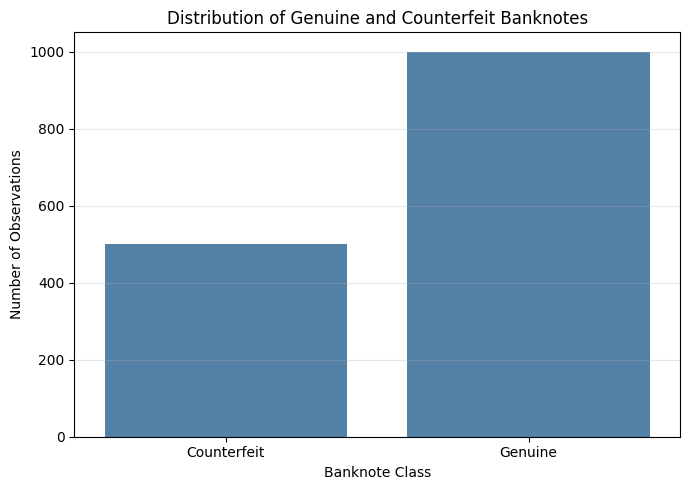

In [66]:
# Step 1: Calculate class distribution
A1_class_counts = df['target'].value_counts().sort_index()

A1_class_summary = pd.DataFrame({
    'Count': A1_class_counts,
    'Percentage': A1_class_counts / len(df) * 100
})

A1_class_summary.index = ['Counterfeit (0)', 'Genuine (1)']

display(A1_class_summary.round(2))

# Step 2: Visualize class distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='target',
    color='steelblue'
)

plt.xticks([0, 1], ['Counterfeit', 'Genuine'])
plt.xlabel('Banknote Class')
plt.ylabel('Number of Observations')
plt.title('Distribution of Genuine and Counterfeit Banknotes')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### A1.2. Data Quality Summary

An initial data quality assessment was conducted to examine the structure, completeness, and consistency of the banknote dataset.

The analysis included:

- Examination of dataset dimensions and feature types.
- Descriptive statistics for numerical features.
- Missing-value counts and missingness by target class.
- Duplicate record detection.
- Detection of identical feature combinations with conflicting labels.
- Assessment of class distribution.

These checks provide the basis for selecting appropriate preprocessing strategies.

The next section will determine how missing observations should be handled, prepare the feature matrix and target variable, and establish an independent train-test split.

The final preprocessing strategy will prioritize data integrity, computational efficiency, and prevention of data leakage.

### A2. Data Cleaning & Train-Test Split

#### Missing Value Treatment

The initial data quality assessment identified 37 observations (2.47%) containing missing feature values.

Missingness differed slightly between classes: 1.60% of counterfeit banknotes and 2.90% of genuine banknotes had incomplete measurements.

Given the relatively small proportion of affected observations, this project uses complete-case analysis to remove rows containing missing values.

After cleaning, 1,463 observations remain. The class distribution changes only slightly, although potential bias due to non-random missingness cannot be completely ruled out.

#### Train-Test Split

The cleaned dataset is divided into:

- **70% training data:** Used for model development, cross-validation, feature selection, and hyperparameter tuning.
- **30% testing data:** Reserved for final, independent model evaluation.

Stratified sampling is applied to preserve the relative proportions of genuine and counterfeit banknotes.

All data-dependent preprocessing, including standardization and PCA, will be fitted using training data only within the appropriate modeling pipelines.

A fixed random seed is used to support reproducibility and comparison with the original experiments.

In [67]:
# Step 1: Remove incomplete observations
A2_df = df.dropna(subset=A1_features.columns).copy()

# Step 2: Verify cleaning results
print(f'Original Records: {len(df)}')
print(f'Cleaned Records: {len(A2_df)}')
print(f'Removed Records: {len(df) - len(A2_df)}')
print(f'Remaining Missing Values: {A2_df.isna().sum().sum()}')

# Step 3: Inspect class distribution after cleaning
A2_class_summary = pd.DataFrame({
    'Count': A2_df['target'].value_counts().sort_index(),
    'Percentage (%)': (
        A2_df['target'].value_counts(normalize=True).sort_index() * 100
    )
})

A2_class_summary.index = ['Counterfeit (0)', 'Genuine (1)']

display(A2_class_summary.round(2))

Original Records: 1500
Cleaned Records: 1463
Removed Records: 37
Remaining Missing Values: 0


,Count,Percentage (%)
Counterfeit (0),492,33.630000000
Genuine (1),971,66.370000000


In [68]:
# Step 1: Define features and target
X = A2_df[A1_features.columns].copy()
y = A2_df['target'].copy()

# Step 2: Stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=21,
    stratify=y
)

# Step 3: Verify split sizes
print(f'Training Samples: {len(X_train)}')
print(f'Testing Samples: {len(X_test)}')

# Step 4: Compare class distributions
A2_split_summary = pd.DataFrame({
    'Full Dataset (%)': y.value_counts(normalize=True) * 100,
    'Training (%)': y_train.value_counts(normalize=True) * 100,
    'Testing (%)': y_test.value_counts(normalize=True) * 100
}).sort_index()

A2_split_summary.index = ['Counterfeit (0)', 'Genuine (1)']

display(A2_split_summary.round(2))

# Step 5: Check train-test overlap by row index
assert set(X_train.index).isdisjoint(set(X_test.index))

print('Train-test split verified.')

Training Samples: 1024
Testing Samples: 439


,Full Dataset (%),Training (%),Testing (%)
Counterfeit (0),33.630000000,33.590000000,33.710000000
Genuine (1),66.370000000,66.410000000,66.290000000


Train-test split verified.


### A2.1. Modeling Dataset Summary

Following data quality assessment and cleaning, the final modeling dataset contains **1,463 complete observations**.

The dataset is divided into 1,024 training observations and 439 testing observations using a stratified 70/30 split.

The independent test set will remain untouched throughout model development.

The training set will be used for:

- Baseline classification model development.
- Stratified five-fold cross-validation.
- Hyperparameter optimization.
- Feature selection and dimensionality reduction.

Preprocessing steps that estimate parameters from data will be incorporated into machine learning pipelines to prevent information leakage.

The next section explores feature distributions, relationships between measurements, and differences between genuine and counterfeit banknotes.

## Part B. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is conducted on the training dataset to understand the statistical characteristics of banknote measurements and identify potential relationships with authenticity.

The analysis focuses on three objectives:

1. **Feature Distributions:** Examine the distribution and variability of numerical features across genuine and counterfeit banknotes.
2. **Correlation Analysis:** Investigate relationships among features and identify potential multicollinearity.
3. **Feature Relationships:** Explore whether combinations of measurements reveal meaningful separation between the two classes.

All exploratory analyses are performed using the training dataset to preserve the independence of the held-out test set.

The findings will inform model selection, preprocessing, and feature selection in subsequent sections.

In [69]:
# Step 1: Prepare training data for EDA
B_eda = X_train.copy()

B_eda['target'] = y_train

B_eda['Banknote Class'] = B_eda['target'].map({
    0: 'Counterfeit',
    1: 'Genuine'
})

# Step 2: Inspect data
print('EDA Dataset Shape:', B_eda.shape)

display(B_eda.head())

# Step 3: Descriptive statistics by class
B_summary = (
    B_eda.groupby('Banknote Class')[X_train.columns.tolist()]
    .agg(['mean', 'std', 'median'])
)

display(B_summary.round(3))

EDA Dataset Shape: (1024, 8)


,diagonal,height_left,height_right,margin_low,margin_up,length,target,Banknote Class
123,514.860000000,104.240000000,103.850000000,4.080000000,2.900000000,112.870000000,1,Genuine
30,515.130000000,103.950000000,103.970000000,4.000000000,2.830000000,113.550000000,1,Genuine
1080,516.690000000,103.830000000,104.290000000,5.610000000,3.470000000,111.720000000,0,Counterfeit
791,515.460000000,103.670000000,103.800000000,4.600000000,3.490000000,113.320000000,1,Genuine
1291,515.520000000,104.460000000,104.150000000,4.510000000,3.390000000,110.730000000,0,Counterfeit


diagonal                             height_left  \
                        mean         std        median          mean   
Banknote Class                                                         
Counterfeit    515.719000000 0.914000000 515.745000000 104.201000000   
Genuine        515.947000000 0.910000000 515.970000000 103.945000000   

                                          height_right              \
                       std        median          mean         std   
Banknote Class                                                       
Counterfeit    0.223000000 104.195000000 104.150000000 0.272000000   
Genuine        0.301000000 103.950000000 103.813000000 0.292000000   

                              margin_low                           margin_up  \
                      median        mean         std      median        mean   
Banknote Class                                                                 
Counterfeit    104.160000000 5.199000000 0.560000000 5.185000000 3.355000000   
Genuine        103.810000000 4.134000000 0.318000000 4.120000000 3.055000000   

                                              length                            
                       std      median          mean         std        median  
Banknote Class                                                                  
Counterfeit    0.181000000 3.360000000 111.630000000 0.606000000 111.630000000  
Genuine        0.188000000 3.050000000 113.211000000 0.357000000 113.210000000

### B1. Feature Distribution Analysis

The distribution of each numerical feature is compared between genuine and counterfeit banknotes.

Boxplots are used to examine:

- Differences in feature medians and variability.
- Overlap between the two classes.
- Potential outliers and extreme measurements.

Features showing substantial differences between classes may provide useful predictive information.

However, visual separation alone does not establish feature importance. Predictive usefulness will be evaluated through cross-validation and feature selection.

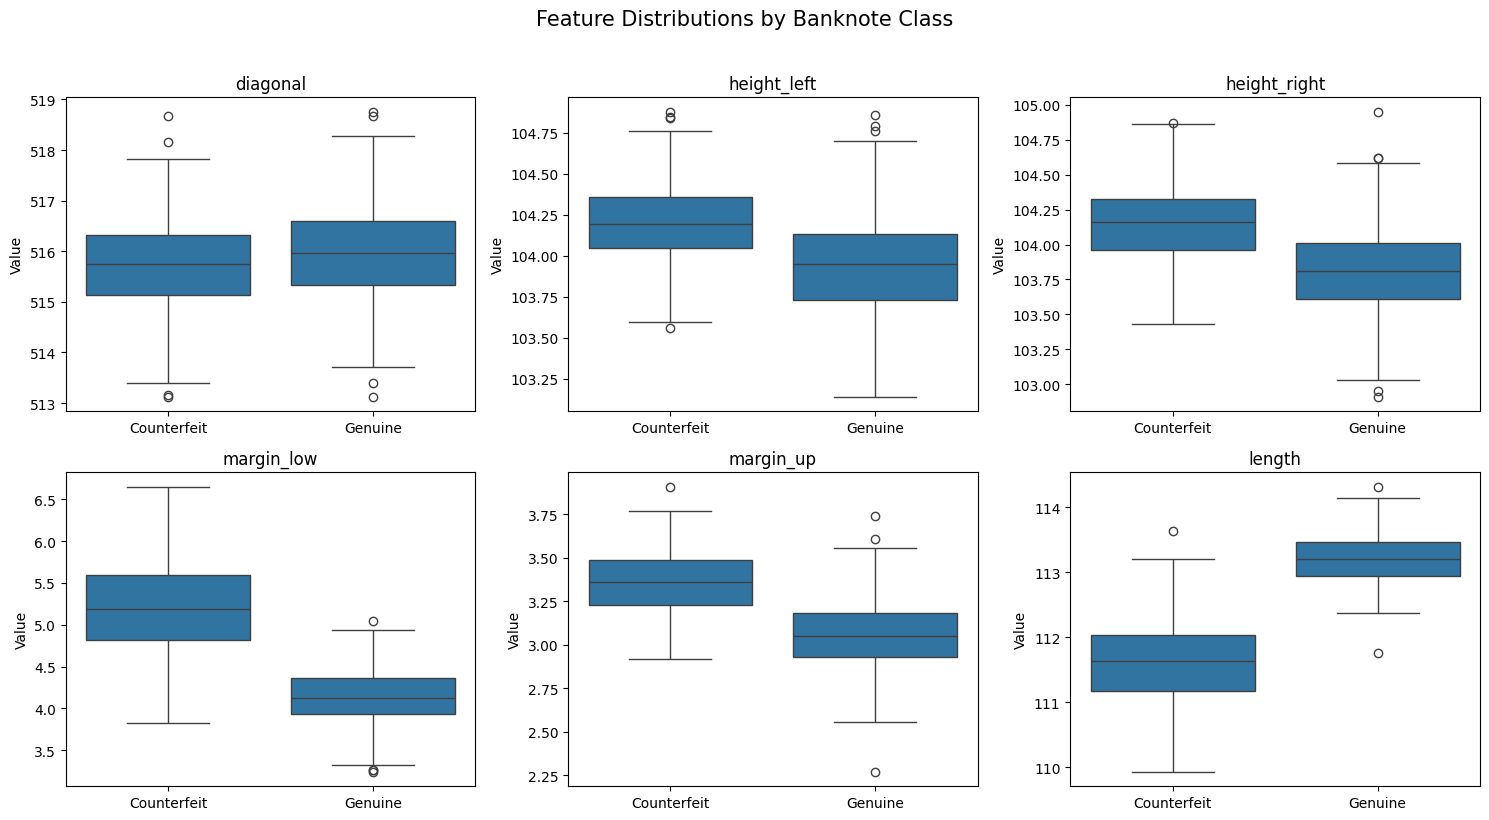

In [70]:
# Step 1: Identify numerical features
B_features = X_train.columns.tolist()

# Step 2: Create boxplots
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, feature in zip(axes.flat, B_features):
    sns.boxplot(
        data=B_eda,
        x='Banknote Class',
        y=feature,
        order=['Counterfeit', 'Genuine'],
        ax=ax
    )

    ax.set_title(feature)
    ax.set_xlabel('')
    ax.set_ylabel('Value')

plt.suptitle(
    'Feature Distributions by Banknote Class',
    fontsize=15,
    y=1.02
)

plt.tight_layout()
plt.show()

### B2. Feature Correlation Analysis

Correlation analysis is used to examine linear relationships among the numerical features.

Strongly correlated features may contain overlapping information, which can influence model complexity and interpretation.

A Pearson correlation matrix is calculated using the training data.

Although correlation can reveal linear associations, it does not establish causality or fully capture nonlinear relationships.

The correlation findings will provide context for subsequent feature selection and PCA experiments.

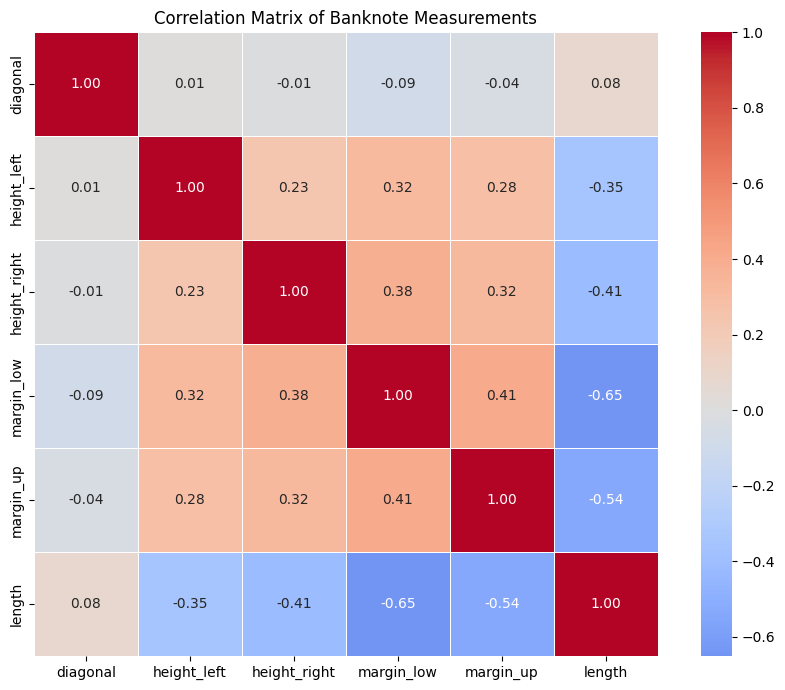

In [71]:
# Step 1: Calculate feature correlations
B_corr = X_train.corr()

# Step 2: Visualize correlation matrix
plt.figure(figsize=(9, 7))

sns.heatmap(
    B_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    square=True,
    linewidths=0.5
)

plt.title('Correlation Matrix of Banknote Measurements')

plt.tight_layout()
plt.show()

### B3. Relationships Between Key Features

Individual feature distributions provide useful information, but classification performance may also depend on interactions between features.

A scatterplot is used to examine how two numerical measurements jointly distinguish genuine and counterfeit banknotes.

The selected feature pair is based on differences observed in the training data.

This visualization is exploratory and does not imply that the selected features are necessarily optimal for classification.

Selected Features: ['length', 'margin_low']


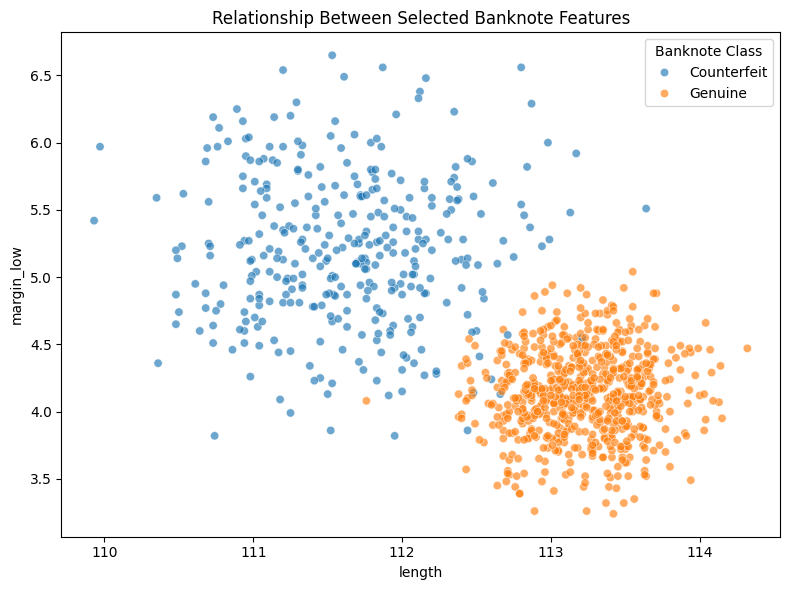

In [72]:
# Step 1: Calculate standardized mean differences
B_class_means = B_eda.groupby('target')[B_features].mean()

B_pooled_std = X_train.std().replace(0, np.nan)

B_mean_diff = (
    (B_class_means.loc[1] - B_class_means.loc[0]).abs()
    / B_pooled_std
)

# Step 2: Select two features
B_top_features = B_mean_diff.nlargest(2).index.tolist()

print('Selected Features:', B_top_features)

# Step 3: Visualize feature relationships
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=B_eda,
    x=B_top_features[0],
    y=B_top_features[1],
    hue='Banknote Class',
    hue_order=['Counterfeit', 'Genuine'],
    alpha=0.65
)

plt.title('Relationship Between Selected Banknote Features')
plt.xlabel(B_top_features[0])
plt.ylabel(B_top_features[1])

plt.tight_layout()
plt.show()

### B4. Exploratory Analysis Summary

The exploratory analysis reveals meaningful differences between genuine and counterfeit banknotes across several numerical measurements.

**1. Feature Distributions**

- `length` and `margin_low` exhibit the clearest class separation among the six individual features.
- Genuine banknotes generally have larger `length` measurements, while counterfeit banknotes tend to have larger `margin_low` measurements.
- `height_left`, `height_right`, and `margin_up` show moderate differences between classes, although their distributions overlap.
- `diagonal` exhibits substantial overlap, suggesting limited individual discriminatory power.

**2. Feature Correlations**

- `length` is negatively correlated with `margin_low` (r = -0.65) and `margin_up` (r = -0.54).
- `margin_low` and `margin_up` show a moderate positive correlation (r = 0.41).
- `diagonal` has weak linear correlations with the other numerical features.

These relationships suggest some shared information among measurements, motivating further investigation using feature selection and PCA.

**3. Class Separation**

A scatterplot of `length` and `margin_low` shows substantial separation between genuine and counterfeit banknotes.

Counterfeit banknotes tend to cluster around shorter lengths and larger lower margins, while genuine banknotes exhibit the opposite pattern.

A limited region of overlap remains, indicating that additional features and nonlinear classification methods may help distinguish ambiguous observations.

**4. Implications for Model Development**

The EDA findings suggest that:

- Distance-based classifiers such as KNN may perform well because the classes form relatively distinct clusters.
- Feature scaling is important for distance-based methods because measurements have different numerical ranges.
- Feature selection may help identify a compact subset of informative measurements.
- Model evaluation should examine errors near the class boundary rather than relying solely on overall accuracy.

These findings are exploratory and will be validated through cross-validation and independent test-set evaluation.

## Part C. Baseline Classification Model Comparison

### C1. Model Development Strategy

Four classification algorithms are evaluated to establish baseline predictive performance:

1. **K-Nearest Neighbors (KNN):** A distance-based classifier that predicts banknote authenticity using nearby observations.
2. **Decision Tree:** A rule-based classifier capable of modeling nonlinear relationships.
3. **Random Forest:** An ensemble of decision trees that reduces prediction variance through averaging.
4. **Bagging:** An ensemble method that trains multiple base estimators on bootstrap samples.

The models are evaluated using **Stratified 5-Fold Cross-Validation** on the training dataset.

The evaluation includes:

- Accuracy
- Precision and Recall
- F1-score
- ROC AUC
- Computational Time

Macro-averaged Precision, Recall, and F1-score are used to give both classes equal importance during initial model comparison.

The held-out test dataset remains excluded from model selection.

### Computational Efficiency

Baseline models are evaluated before hyperparameter tuning to identify promising candidates.

This approach reduces unnecessary computation and allows subsequent optimization to focus on models that demonstrate competitive cross-validation performance.

In [73]:
# C1: Define baseline classifiers
C1_models = {
    'KNN': Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(n_neighbors=5))
    ]),

    'Decision Tree': DecisionTreeClassifier(
        random_state=21
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=21,
        n_jobs=1
    ),

    'Bagging': BaggingClassifier(
        n_estimators=100,
        random_state=21,
        n_jobs=1
    )
}

print('Baseline Models:')
for name in C1_models:
    print('-', name)

Baseline Models:
- KNN
- Decision Tree
- Random Forest
- Bagging


### C2. Cross-Validation and Evaluation Metrics

Stratified 5-Fold Cross-Validation is used to evaluate model performance.

In each fold, approximately 80% of the training observations are used for model fitting, while the remaining 20% are used for validation.

Stratification preserves the relative distribution of genuine and counterfeit banknotes.

The following metrics are reported:

- **Accuracy:** Overall proportion of correctly classified observations.
- **Macro Precision:** Average precision across both banknote classes.
- **Macro Recall:** Average recall across both classes.
- **Macro F1-score:** Average F1-score across both classes.
- **ROC AUC:** Ability to distinguish between the two classes across classification thresholds.

Mean cross-validation scores and their standard deviations are used to assess predictive performance and stability.

Computational time is also recorded to compare model efficiency.

In [74]:
import time

# C2: Define evaluation metrics
C2_scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision_macro',
    'Recall': 'recall_macro',
    'F1': 'f1_macro',
    'ROC_AUC': 'roc_auc'
}

# C2: Evaluate baseline models
C2_results = []

for name, model in C1_models.items():

    start = time.perf_counter()

    cv_scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=CV,
        scoring=C2_scoring,
        n_jobs=-1,
        error_score='raise'
    )

    elapsed = time.perf_counter() - start

    C2_results.append({
        'Model': name,
        'Accuracy': cv_scores['test_Accuracy'].mean(),
        'Accuracy Std': cv_scores['test_Accuracy'].std(),
        'Precision': cv_scores['test_Precision'].mean(),
        'Recall': cv_scores['test_Recall'].mean(),
        'F1': cv_scores['test_F1'].mean(),
        'ROC AUC': cv_scores['test_ROC_AUC'].mean(),
        'Time (s)': elapsed
    })

# C2: Display results
C2_summary = pd.DataFrame(C2_results)

C2_summary = (
    C2_summary
    .sort_values('F1', ascending=False)
    .reset_index(drop=True)
)

display(C2_summary.round(9))

,Model,Accuracy,Accuracy Std,Precision,Recall,F1,ROC AUC,Time (s)
0,Random Forest,0.991214730,0.003645294,0.992028679,0.988384484,0.990106626,0.999264706,1.759082556
1,KNN,0.988283118,0.003897701,0.990573809,0.983280051,0.986766364,0.993094002,2.368493653
2,Bagging,0.984380679,0.008385860,0.982689697,0.982523444,0.982516107,0.997058824,1.997780613
3,Decision Tree,0.983405069,0.007917669,0.981959348,0.981052856,0.981410888,0.981052856,0.148510142


### C3. Baseline Model Performance Comparison

The four baseline classifiers are compared using mean Stratified 5-Fold Cross-Validation scores.

The primary evaluation metric is **Macro F1-score**, which balances precision and recall while assigning equal weight to genuine and counterfeit banknotes.

Accuracy and ROC AUC are also considered to assess overall classification performance and class discrimination.

Computational time is included to evaluate the trade-off between predictive performance and model complexity.

The comparison provides an empirical basis for selecting models for subsequent hyperparameter tuning.

No conclusions about final generalization performance are drawn from the baseline cross-validation scores alone.

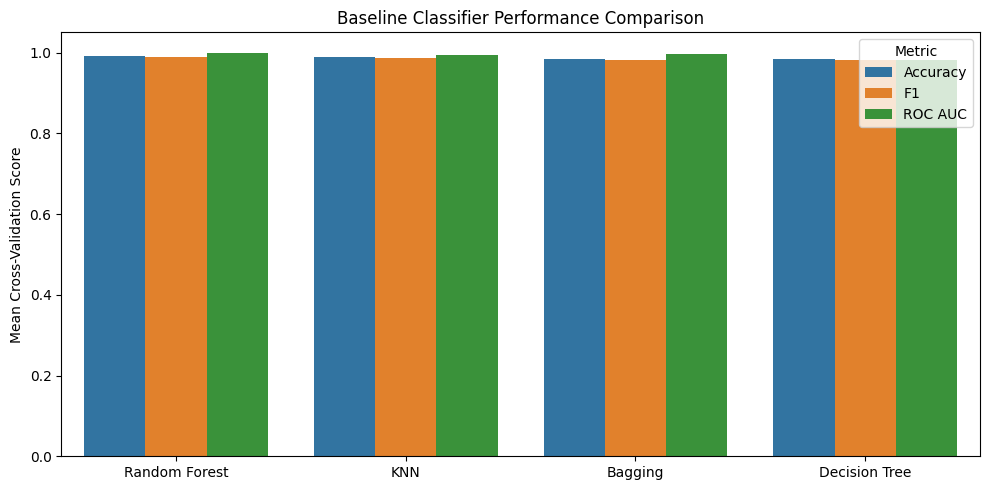

In [75]:
# C3: Prepare model comparison
C3_plot_data = C2_summary.melt(
    id_vars='Model',
    value_vars=['Accuracy', 'F1', 'ROC AUC'],
    var_name='Metric',
    value_name='Score'
)

# C3: Visualize baseline performance
plt.figure(figsize=(10, 5))

sns.barplot(
    data=C3_plot_data,
    x='Model',
    y='Score',
    hue='Metric'
)

plt.ylim(0, 1.05)
plt.xlabel('')
plt.ylabel('Mean Cross-Validation Score')
plt.title('Baseline Classifier Performance Comparison')

plt.legend(title='Metric')
plt.tight_layout()
plt.show()

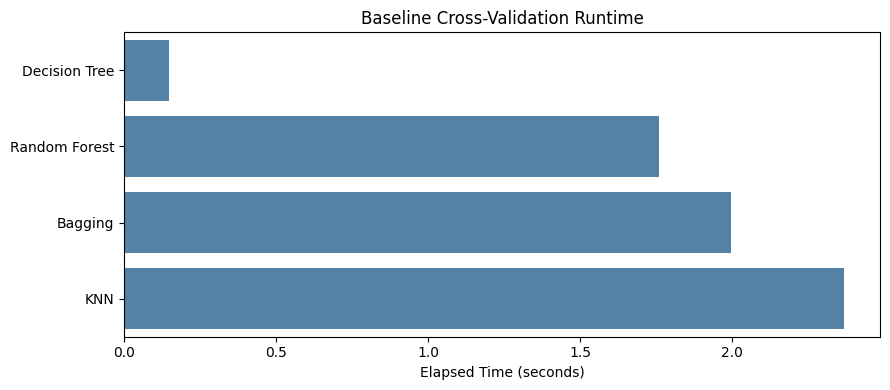

In [76]:
# C3: Compare computational time
C3_time = C2_summary.sort_values('Time (s)')

plt.figure(figsize=(9, 4))

sns.barplot(
    data=C3_time,
    x='Time (s)',
    y='Model',
    color='steelblue'
)

plt.title('Baseline Cross-Validation Runtime')
plt.xlabel('Elapsed Time (seconds)')
plt.ylabel('')

plt.tight_layout()
plt.show()

## Part D. Efficient Hyperparameter Optimization

### D1. Model Selection for Tuning

The baseline comparison identified Random Forest and KNN as the strongest candidates, with mean cross-validation Macro F1-scores of 0.9901 and 0.9868, respectively.

Random Forest achieved the highest overall performance, while KNN remained competitive as a relatively simple distance-based classifier.

To balance predictive performance and computational efficiency, hyperparameter optimization focuses on these two models.

- **KNN:** Grid search over a limited range of neighbor counts and weighting strategies.
- **Random Forest:** Randomized search over tree complexity and ensemble parameters.

Both methods use Stratified 5-Fold Cross-Validation and optimize Macro F1-score.

The held-out test set remains excluded from the tuning process. Feature selection will be evaluated separately in the following section.

In [77]:
# D1: Define KNN pipeline
D1_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier())
])

# D1: Parameter grid
D1_knn_params = {
    'model__n_neighbors': [1, 3, 5, 7, 9, 11, 15, 21],
    'model__weights': ['uniform', 'distance']
}

# D1: Run grid search
D1_start = time.perf_counter()

D1_knn_search = GridSearchCV(
    estimator=D1_knn,
    param_grid=D1_knn_params,
    scoring='f1_macro',
    cv=CV,
    n_jobs=1,
    refit=True
)

D1_knn_search.fit(X_train, y_train)

D1_knn_time = time.perf_counter() - D1_start

print('Best KNN Parameters:', D1_knn_search.best_params_)
print(f'Best CV Macro F1: {D1_knn_search.best_score_:.9f}')
print(f'Tuning Time: {D1_knn_time:.2f} seconds')

Best KNN Parameters: {'model__n_neighbors': 15, 'model__weights': 'uniform'}
Best CV Macro F1: 0.986801948
Tuning Time: 0.91 seconds


In [78]:
# D2: Define Random Forest
D2_rf = RandomForestClassifier(
    random_state=21,
    n_jobs=1
)

# D2: Parameter distributions
D2_rf_params = {
    'n_estimators': [80, 120, 200],
    'max_depth': [None, 5, 10, 15],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', None]
}

# D2: Run randomized search
D2_start = time.perf_counter()

D2_rf_search = RandomizedSearchCV(
    estimator=D2_rf,
    param_distributions=D2_rf_params,
    n_iter=12,
    scoring='f1_macro',
    cv=CV,
    random_state=21,
    n_jobs=1,
    refit=True
)

D2_rf_search.fit(X_train, y_train)

D2_rf_time = time.perf_counter() - D2_start

print('Best RF Parameters:', D2_rf_search.best_params_)
print(f'Best CV Macro F1: {D2_rf_search.best_score_:.9f}')
print(f'Tuning Time: {D2_rf_time:.2f} seconds')

Best RF Parameters: {'n_estimators': 200, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 5}
Best CV Macro F1: 0.991205557
Tuning Time: 21.39 seconds


In [79]:
# D3: Compare cross-validation performance
D3_comparison = pd.DataFrame({
    'Model': [
        'KNN Baseline',
        'KNN Tuned',
        'RF Baseline',
        'RF Tuned'
    ],
    'CV Macro F1': [
        C2_summary.loc[
            C2_summary['Model'] == 'KNN', 'F1'
        ].iloc[0],
        D1_knn_search.best_score_,
        C2_summary.loc[
            C2_summary['Model'] == 'Random Forest', 'F1'
        ].iloc[0],
        D2_rf_search.best_score_
    ]
})

display(D3_comparison.round(9))

,Model,CV Macro F1
0,KNN Baseline,0.986766364
1,KNN Tuned,0.986801948
2,RF Baseline,0.990106626
3,RF Tuned,0.991205557


### D3. Hyperparameter Tuning Findings

Hyperparameter tuning was conducted for KNN and Random Forest using Stratified 5-Fold Cross-Validation, with Macro F1-score as the optimization metric.

**KNN**

The best KNN configuration used 15 neighbors with uniform weighting. Its mean CV Macro F1-score increased slightly from 0.986766364 to 0.986801948, representing a negligible improvement in predictive performance.

**Random Forest**

The best configuration used 200 estimators, a maximum depth of 5, a minimum of 2 samples per leaf, and square-root feature sampling.

The mean CV Macro F1-score increased from 0.9901 to 0.9912. However, the improvement was small and should not be interpreted as evidence of a substantial performance gain.

**Computational Efficiency**

The restricted search spaces reduced unnecessary experimentation while preserving competitive classification performance.

Further broad hyperparameter searches are unlikely to be a productive use of computational resources at this stage.

The next section evaluates whether feature selection and dimensionality reduction can maintain predictive performance with fewer input variables.

## Part E. Feature Selection & Dimensionality Reduction

### E1. Five-Feature Ablation Study

The original dataset contains six numerical measurements. Although all features may contribute predictive information, a smaller subset could potentially achieve comparable performance.

To evaluate this possibility efficiently, a five-feature ablation study is performed using the tuned KNN classifier.

Each experiment removes one feature while retaining the other five. The resulting feature subsets are evaluated using Stratified 5-Fold Cross-Validation.

This approach requires only six candidate subsets and provides an interpretable assessment of feature redundancy.

The experiment focuses on:

- Predictive performance with five versus six features.
- Identifying features whose removal has minimal impact.
- Reducing model input dimensionality without substantially sacrificing classification performance.

Feature selection is performed exclusively on the training dataset. Cross-validation scores are used for model selection, while final generalization performance will be assessed on the held-out test set.

In [80]:
from sklearn.model_selection import cross_val_score

# E1: Reuse tuned KNN configuration
E1_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier(
        n_neighbors=D1_knn_search.best_params_['model__n_neighbors'],
        weights=D1_knn_search.best_params_['model__weights']
    ))
])

# E1: Evaluate each five-feature subset
E1_results = []

for removed_feature in X_train.columns:
    selected_features = [
        col for col in X_train.columns
        if col != removed_feature
    ]

    scores = cross_val_score(
        E1_knn,
        X_train[selected_features],
        y_train,
        cv=CV,
        scoring='f1_macro',
        n_jobs=1
    )

    E1_results.append({
        'Removed Feature': removed_feature,
        'CV Macro F1': scores.mean(),
        'CV Std': scores.std()
    })

# E1: Rank feature subsets
E1_summary = pd.DataFrame(E1_results).sort_values(
    'CV Macro F1', ascending=False
).reset_index(drop=True)

display(E1_summary.round(9))

# E1: Identify the best five-feature subset
E1_removed_feature = E1_summary.loc[0, 'Removed Feature']

E1_selected_features = [
    col for col in X_train.columns
    if col != E1_removed_feature
]

print('Best Five-Feature Subset:', E1_selected_features)
print('Removed Feature:', E1_removed_feature)

,Removed Feature,CV Macro F1,CV Std
0,diagonal,0.986801948,0.004380520
1,height_right,0.986777767,0.005608249
2,height_left,0.985656280,0.005645829
3,margin_up,0.978938947,0.006539675
4,margin_low,0.963393224,0.021376169
5,length,0.946728242,0.017917564


Best Five-Feature Subset: ['height_left', 'height_right', 'margin_low', 'margin_up', 'length']
Removed Feature: diagonal


In [81]:
# E1: Evaluate all six features
E1_full_scores = cross_val_score(
    E1_knn,
    X_train,
    y_train,
    cv=CV,
    scoring='f1_macro',
    n_jobs=1
)

E1_comparison = pd.DataFrame({
    'Feature Set': ['All Six Features', 'Best Five Features'],
    'Number of Features': [6, 5],
    'CV Macro F1': [
        E1_full_scores.mean(),
        E1_summary.loc[0, 'CV Macro F1']
    ]
})

display(E1_comparison.round(9))

,Feature Set,Number of Features,CV Macro F1
0,All Six Features,6,0.986801948
1,Best Five Features,5,0.986801948


### E2. Principal Component Analysis

Principal Component Analysis (PCA) is evaluated as an alternative dimensionality reduction approach.

Unlike feature selection, which retains original measurements, PCA transforms the standardized input variables into new orthogonal components.

The number of retained components is varied from two to six.

A pipeline is used to ensure that standardization and PCA are fitted only on the training portion of each cross-validation fold.

The resulting KNN performance will be compared with the original six-feature model and the selected five-feature subset.

This analysis investigates whether dimensionality reduction can simplify the input representation while maintaining predictive performance.

In [82]:
from sklearn.decomposition import PCA

# E2: Evaluate PCA dimensionality
E2_results = []

for n_components in range(2, 7):

    pca_knn = Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=n_components)),
        ('model', KNeighborsClassifier(
            n_neighbors=D1_knn_search.best_params_['model__n_neighbors'],
            weights=D1_knn_search.best_params_['model__weights']
        ))
    ])

    scores = cross_val_score(
        pca_knn,
        X_train,
        y_train,
        cv=CV,
        scoring='f1_macro',
        n_jobs=1
    )

    E2_results.append({
        'PCA Components': n_components,
        'CV Macro F1': scores.mean(),
        'CV Std': scores.std()
    })

E2_summary = pd.DataFrame(E2_results)

display(E2_summary.round(9))

,PCA Components,CV Macro F1,CV Std
0,2,0.982399738,0.007332466
1,3,0.982436131,0.002220697
2,4,0.983502859,0.004914582
3,5,0.984590758,0.004111312
4,6,0.986801948,0.004380520


Feature Reduction Comparison:
               Method  CV Macro F1     Delta F1
Original (6 Features)  0.986801948  0.000000000
Ablation (5 Features)  0.986801948 -0.000000000
             Best PCA  0.986801948  0.000000000

Feature Ablation Results:
Removed Feature  CV Macro F1      CV Std     F1 Drop
         length  0.946728242 0.017917564 0.040073706
     margin_low  0.963393224 0.021376169 0.023408724
      margin_up  0.978938947 0.006539675 0.007863002
    height_left  0.985656280 0.005645829 0.001145668
   height_right  0.986777767 0.005608249 0.000024181
       diagonal  0.986801948 0.004380520 0.000000000

PCA Results:
 PCA Components  CV Macro F1      CV Std
              2  0.982399738 0.007332466
              3  0.982436131 0.002220697
              4  0.983502859 0.004914582
              5  0.984590758 0.004111312
              6  0.986801948 0.004380520


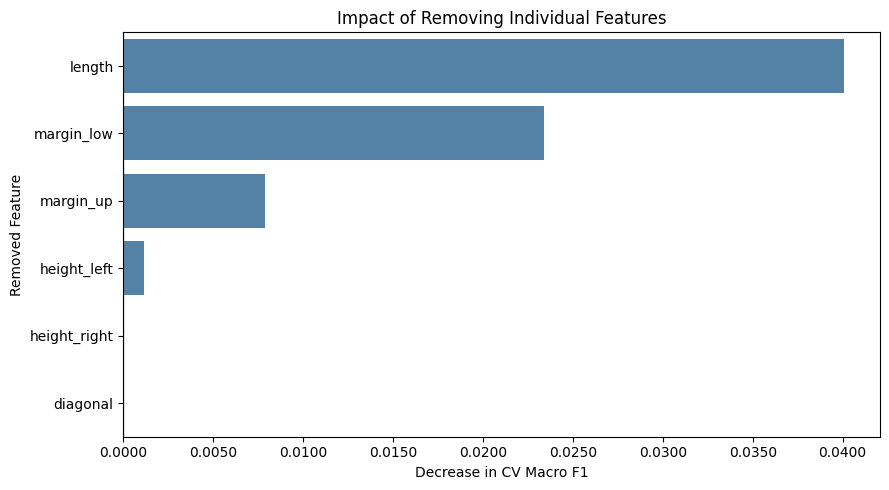

In [83]:
# E3: Compare feature reduction methods
E3_comparison = pd.DataFrame({
    'Method': [
        'Original (6 Features)',
        'Ablation (5 Features)',
        'Best PCA'
    ],
    'CV Macro F1': [
        E1_full_scores.mean(),
        E1_summary['CV Macro F1'].max(),
        E2_summary['CV Macro F1'].max()
    ]
})

E3_comparison['Delta F1'] = (
    E3_comparison['CV Macro F1']
    - E1_full_scores.mean()
)

print('Feature Reduction Comparison:')
print(E3_comparison.to_string(index=False, float_format='%.9f'))

# E3: Feature ablation analysis
E3_ablation = E1_summary.copy()

E3_ablation['F1 Drop'] = (
    E1_full_scores.mean()
    - E3_ablation['CV Macro F1']
)

E3_ablation = E3_ablation.sort_values(
    'F1 Drop', ascending=False
)

print('\nFeature Ablation Results:')
print(E3_ablation.to_string(index=False, float_format='%.9f'))

print('\nPCA Results:')
print(E2_summary.to_string(index=False, float_format='%.9f'))

# E3: Plot feature ablation impact
fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=E3_ablation,
    x='F1 Drop',
    y='Removed Feature',
    color='steelblue',
    ax=ax
)

ax.axvline(0, color='gray', linewidth=1)

ax.set_title('Impact of Removing Individual Features')
ax.set_xlabel('Decrease in CV Macro F1')
ax.set_ylabel('Removed Feature')

ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f'{x:.4f}')
)

plt.tight_layout()
plt.show()

### E4. Feature Reduction Findings

The feature reduction experiments evaluated whether the six original measurements could be simplified without compromising KNN classification performance.

**1. Five-Feature Ablation**

Removing `diagonal` produced the same mean CV Macro F1-score as the full six-feature model (**0.986801948**).

Removing `height_right` resulted in a negligible decrease of **0.000024181**, while removing `length` or `margin_low` caused substantially larger performance reductions of **0.040073706** and **0.023408724**, respectively.

These findings suggest that `length` and `margin_low` contain particularly valuable classification information, consistent with the earlier EDA observations.

The five-feature subset excluding `diagonal` is therefore a promising candidate for further evaluation.

**2. PCA Comparison**

PCA with all six components achieved a mean CV Macro F1-score of **0.986801948**, identical to the original feature representation.

Reducing PCA to five components lowered the score to **0.984590758**, while retaining only two components resulted in **0.982399738**.

The results indicate that PCA did not improve predictive performance in the evaluated configurations.

**3. Key Takeaways**

- Removing `diagonal` maintained the original KNN cross-validation performance while reducing the feature count from six to five.
- `length` and `margin_low` had the largest observed impact on KNN performance when individually removed.
- PCA did not offer a clear predictive advantage over the original features.
- The five-feature KNN model is retained as an interpretable, lower-dimensional candidate for final evaluation.

These conclusions are based on training-set cross-validation results. Small differences between feature subsets should not be interpreted as statistically significant improvements.

## Part F. Final Model Evaluation

### F1. Evaluation Strategy

Following baseline comparison, hyperparameter optimization, and feature reduction experiments, three candidate models are retained for final evaluation:

1. **Tuned Random Forest:** The highest-performing model during training-set cross-validation, using all six features.
2. **Tuned KNN:** A distance-based classifier using all six features.
3. **Five-Feature KNN:** The tuned KNN classifier excluding `diagonal`, which maintained the same mean cross-validation Macro F1-score as the full-feature KNN model.

All model configurations were determined using training data only.

The models are now fitted on the complete training dataset and evaluated on the previously untouched test dataset.

The final evaluation includes:

- Accuracy
- Macro Precision, Recall, and F1-score
- ROC AUC
- Confusion Matrix
- Counterfeit Detection Recall
- False Acceptance Rate
- False Rejection Rate

The tuned Random Forest is the primary model selected from cross-validation. The two KNN variants are evaluated as predefined comparators.

Test results will be reported without further hyperparameter adjustments or feature selection to avoid test-set-driven optimization.

In [84]:
# F1: Define final candidate models
F1_models = {
    'Tuned Random Forest': clone(
        D2_rf_search.best_estimator_
    ),

    'Tuned KNN (6 Features)': clone(
        D1_knn_search.best_estimator_
    ),

    'Tuned KNN (5 Features)': clone(
        D1_knn_search.best_estimator_
    )
}

# F1: Define feature subsets
F1_features = {
    'Tuned Random Forest': X_train.columns.tolist(),
    'Tuned KNN (6 Features)': X_train.columns.tolist(),
    'Tuned KNN (5 Features)': E1_selected_features
}

# F1: Fit each model on complete training data
for name, model in F1_models.items():
    features = F1_features[name]

    model.fit(X_train[features], y_train)

    print(f'{name}: Training completed')

Tuned Random Forest: Training completed
Tuned KNN (6 Features): Training completed
Tuned KNN (5 Features): Training completed


### F2. Classification Performance Metrics

The final models are evaluated on held-out observations using multiple performance metrics.

**Overall Classification Metrics**

- **Accuracy:** Proportion of correctly classified banknotes.
- **Macro Precision:** Average precision across genuine and counterfeit classes.
- **Macro Recall:** Average recall across both classes.
- **Macro F1-score:** Harmonic mean of precision and recall, averaged equally across classes.
- **ROC AUC:** Measures class discrimination across classification thresholds.

**Counterfeit Detection Metrics**

The dataset uses `0` for counterfeit banknotes and `1` for genuine banknotes.

For counterfeit detection, counterfeit banknotes are treated as the operational positive class.

Two types of errors are especially important:

- **False Acceptance:** A counterfeit banknote is incorrectly classified as genuine.
- **False Rejection:** A genuine banknote is incorrectly classified as counterfeit.

Counterfeit Recall measures the proportion of counterfeit banknotes correctly detected.

False Acceptance Rate measures the proportion of actual counterfeit banknotes incorrectly accepted as genuine.

False Rejection Rate measures the proportion of genuine banknotes incorrectly rejected as counterfeit.

These metrics help assess classification performance beyond overall accuracy.

In [85]:
# F2: Evaluate final models
F2_results = []
F2_predictions = {}
F2_probabilities = {}

for name, model in F1_models.items():

    features = F1_features[name]
    X_eval = X_test[features]

    y_pred = model.predict(X_eval)
    y_prob = model.predict_proba(X_eval)[:, 1]

    F2_predictions[name] = y_pred
    F2_probabilities[name] = y_prob

    # Counterfeit is encoded as class 0
    counterfeit_recall = recall_score(
        y_test, y_pred, pos_label=0
    )

    genuine_recall = recall_score(
        y_test, y_pred, pos_label=1
    )

    F2_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Macro Precision': precision_score(
            y_test, y_pred, average='macro'
        ),
        'Macro Recall': recall_score(
            y_test, y_pred, average='macro'
        ),
        'Macro F1': f1_score(
            y_test, y_pred, average='macro'
        ),
        'ROC AUC': roc_auc_score(y_test, y_prob),
        'Counterfeit Recall': counterfeit_recall,
        'False Acceptance Rate': 1 - counterfeit_recall,
        'False Rejection Rate': 1 - genuine_recall
    })

F2_summary = pd.DataFrame(F2_results)

print(F2_summary.to_string(
    index=False,
    float_format='%.9f'
))

                 Model    Accuracy  Macro Precision  Macro Recall    Macro F1     ROC AUC  Counterfeit Recall  False Acceptance Rate  False Rejection Rate
   Tuned Random Forest 0.988610478      0.986484610   0.988088604 0.987279566 0.999349865         0.986486486            0.013513514           0.010309278
Tuned KNN (6 Features) 0.993166287      0.994897959   0.989864865 0.992316444 0.995971487         0.979729730            0.020270270           0.000000000
Tuned KNN (5 Features) 0.990888383      0.993220339   0.986486486 0.989737716 0.999558837         0.972972973            0.027027027           0.000000000


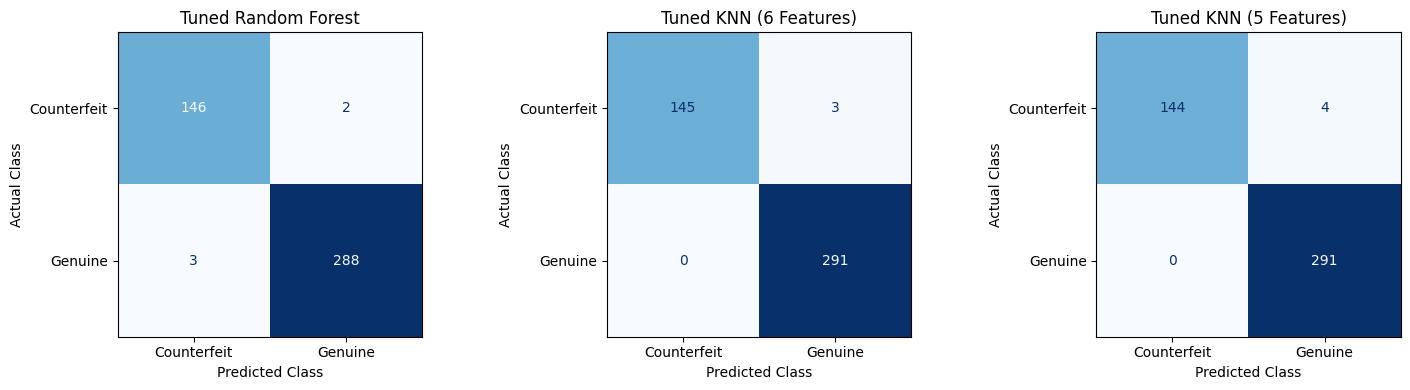

In [86]:
# F3: Compare confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, y_pred) in zip(
    axes, F2_predictions.items()
):

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=[0, 1],
        display_labels=['Counterfeit', 'Genuine'],
        cmap='Blues',
        colorbar=False,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted Class')
    ax.set_ylabel('Actual Class')

plt.tight_layout()
plt.show()

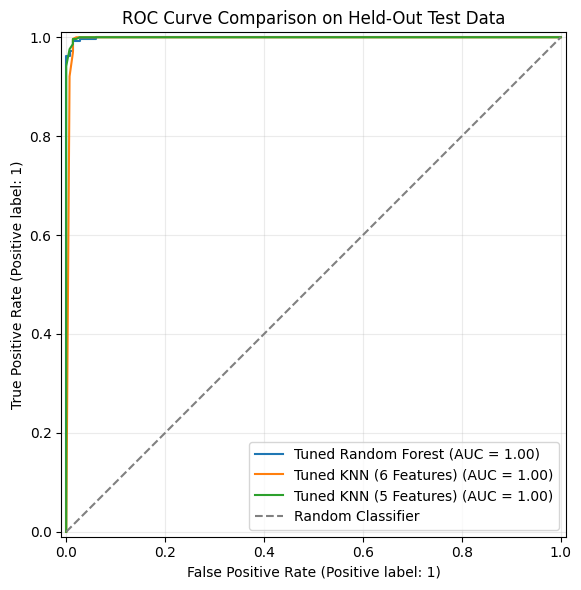

In [87]:
# F4: Compare ROC curves
fig, ax = plt.subplots(figsize=(7, 6))

for name, y_prob in F2_probabilities.items():

    RocCurveDisplay.from_predictions(
        y_test,
        y_prob,
        name=name,
        ax=ax
    )

ax.plot(
    [0, 1], [0, 1],
    linestyle='--',
    color='gray',
    label='Random Classifier'
)

ax.set_title('ROC Curve Comparison on Held-Out Test Data')
ax.grid(alpha=0.25)
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

### F5. Final Evaluation Findings

Three predefined classification models were evaluated on the held-out test dataset containing 439 banknotes.

**Overall Classification Performance**

The six-feature KNN classifier achieved the highest test accuracy (99.3166%) and Macro F1-score (0.992316), with only three misclassified observations.

The tuned Random Forest achieved an accuracy of 98.8610% and a Macro F1-score of 0.987280. Although it performed best during cross-validation, it did not achieve the highest overall test-set classification performance.

The five-feature KNN classifier achieved 99.0888% accuracy, demonstrating that removing `diagonal` preserved competitive performance, although its test results were slightly weaker than those of the six-feature KNN.

**Counterfeit Detection Performance**

The Random Forest incorrectly accepted two counterfeit banknotes as genuine and incorrectly rejected three genuine banknotes.

The six-feature KNN incorrectly accepted three counterfeit banknotes but did not reject any genuine banknotes.

The five-feature KNN incorrectly accepted four counterfeit banknotes and did not reject any genuine banknotes.

These findings highlight a trade-off between overall classification accuracy and counterfeit detection.

**Key Findings**

- Six-feature KNN achieved the highest overall accuracy and Macro F1-score.
- Random Forest achieved the highest counterfeit recall at the default classification threshold.
- Five-feature KNN remained competitive with fewer measurements.
- All three models demonstrated strong discrimination, with ROC AUC exceeding 0.995.

The results are based on a single held-out test split. Small performance differences should not be interpreted as statistically significant superiority.

The next section examines classification thresholds and the operational implications of false acceptance and false rejection.

## Part G. Counterfeit Detection Risk Analysis

### G1. Classification Errors and Operational Risk

In counterfeit banknote detection, different prediction errors may have different operational consequences.

**False Acceptance (FA)** occurs when a counterfeit banknote is classified as genuine. This may expose a financial institution to direct financial loss.

**False Rejection (FR)** occurs when a genuine banknote is classified as counterfeit. This may result in unnecessary manual verification, delays, or customer inconvenience.

The default classification threshold does not necessarily reflect these different operational costs.

This section investigates how changing the counterfeit probability threshold affects false acceptance and false rejection rates.

The tuned Random Forest is used for this analysis because it was selected as the primary model during cross-validation and achieved the highest counterfeit recall in the held-out evaluation.

To avoid selecting thresholds using test data, threshold analysis is performed using out-of-fold predictions from the training dataset.

Since the model's hyperparameters were previously selected using the same training data, this analysis is exploratory rather than a fully independent validation of threshold performance.

In [88]:
from sklearn.model_selection import cross_val_predict

# G1: Generate out-of-fold probabilities on training data
G1_model = clone(D2_rf_search.best_estimator_)

G1_prob = cross_val_predict(
    G1_model,
    X_train,
    y_train,
    cv=CV,
    method='predict_proba',
    n_jobs=1
)

# Counterfeit = class 0
G1_counterfeit_prob = G1_prob[:, 0]

print('OOF Predictions:', len(G1_counterfeit_prob))
print('Counterfeit Probability Range:',
      G1_counterfeit_prob.min(),
      G1_counterfeit_prob.max())

OOF Predictions: 1024
Counterfeit Probability Range: 0.0004551586166736423 0.9997605621880342


In [89]:
# G2: Evaluate counterfeit probability thresholds
G2_thresholds = np.arange(0.2, 0.81, 0.1)
G2_results = []

G2_actual = y_train.to_numpy()

for threshold in G2_thresholds:

    # Classify as counterfeit if probability >= threshold
    y_pred = np.where(
        G1_counterfeit_prob >= threshold, 0, 1
    )

    cm = confusion_matrix(
        G2_actual, y_pred, labels=[0, 1]
    )

    detected, false_accepted = cm[0]
    false_rejected, accepted = cm[1]

    G2_results.append({
        'Threshold': threshold,
        'False Acceptance Rate': (
            false_accepted / (detected + false_accepted)
        ),
        'False Rejection Rate': (
            false_rejected / (false_rejected + accepted)
        ),
        'False Acceptances': false_accepted,
        'False Rejections': false_rejected
    })

G2_summary = pd.DataFrame(G2_results)

print(G2_summary.to_string(
    index=False,
    float_format='%.9f'
))

  Threshold  False Acceptance Rate  False Rejection Rate  False Acceptances  False Rejections
0.200000000            0.002906977           0.027941176                  1                19
0.300000000            0.011627907           0.016176471                  4                11
0.400000000            0.020348837           0.005882353                  7                 4
0.500000000            0.020348837           0.001470588                  7                 1
0.600000000            0.029069767           0.001470588                 10                 1
0.700000000            0.046511628           0.001470588                 16                 1
0.800000000            0.081395349           0.001470588                 28                 1


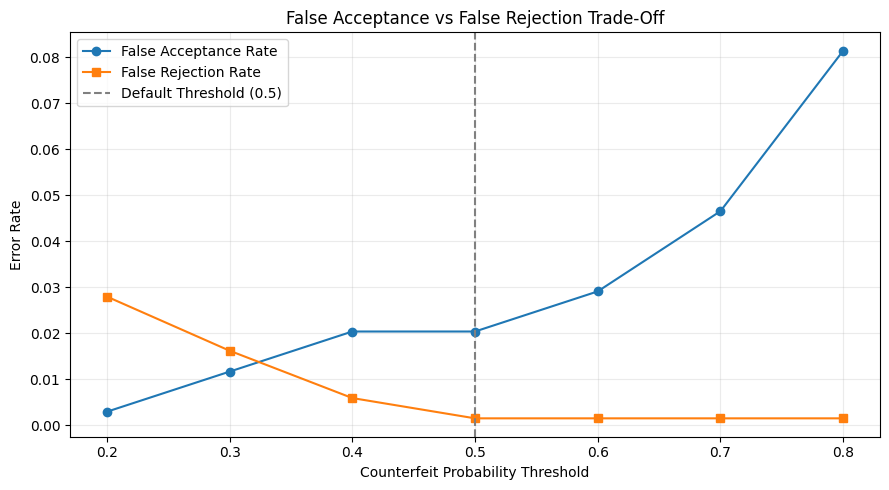

In [90]:
# G3: Plot classification risk across thresholds
plt.figure(figsize=(9, 5))

plt.plot(
    G2_summary['Threshold'],
    G2_summary['False Acceptance Rate'],
    marker='o',
    label='False Acceptance Rate'
)

plt.plot(
    G2_summary['Threshold'],
    G2_summary['False Rejection Rate'],
    marker='s',
    label='False Rejection Rate'
)

plt.axvline(
    0.5,
    linestyle='--',
    color='gray',
    label='Default Threshold (0.5)'
)

plt.xlabel('Counterfeit Probability Threshold')
plt.ylabel('Error Rate')
plt.title('False Acceptance vs False Rejection Trade-Off')
plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### G4. Risk Analysis Findings

The threshold analysis reveals a trade-off between counterfeit detection and genuine banknote acceptance.

Out-of-fold predictions were generated for 1,024 training observations, including 344 counterfeit and 680 genuine banknotes.

**1. Default Classification Threshold**

At the default counterfeit probability threshold of 0.5:

- 7 counterfeit banknotes were incorrectly accepted as genuine.
- 1 genuine banknote was incorrectly rejected.
- The False Acceptance Rate was 2.03%.
- The False Rejection Rate was 0.15%.

**2. Lower Detection Thresholds**

Reducing the threshold from 0.5 to 0.2 decreased false acceptances from 7 to 1, an 85.7% reduction.

However, false rejections increased from 1 to 19, demonstrating the cost of more aggressive counterfeit detection.

A threshold of 0.3 provided an intermediate trade-off, with 4 false acceptances and 11 false rejections.

**3. Threshold Efficiency**

At a threshold of 0.4, the model produced the same number of false acceptances as at 0.5, but more false rejections.

Increasing the threshold above 0.5 increased false acceptances without reducing false rejections in the evaluated range.

Therefore, thresholds of 0.2, 0.3, and 0.5 represent the most relevant trade-off candidates among the evaluated values.

**4. Operational Implications**

A lower threshold may be appropriate when counterfeit acceptance is associated with high financial losses.

A higher threshold may be preferable when minimizing unnecessary manual verification and customer disruption is the primary objective.

However, selecting an optimal operational threshold requires reliable estimates of error costs, transaction context, and risk tolerance.

These findings are based on out-of-fold predictions from the training dataset. They should be interpreted as exploratory sensitivity analysis rather than independently validated operational performance.

## Part H. Conclusions & Limitations

### H1. Project Conclusions

This project developed and evaluated machine learning models for counterfeit banknote classification, emphasizing predictive performance, feature efficiency, and classification risk.

**1. Classification Performance**

Four baseline classifiers were compared using Stratified 5-Fold Cross-Validation: KNN, Decision Tree, Random Forest, and Bagging.

Random Forest achieved the strongest baseline cross-validation performance, while KNN remained highly competitive.

After hyperparameter tuning, Random Forest achieved a mean CV Macro F1-score of 0.9912.

On the held-out test set of 439 observations:

- Six-feature KNN achieved the highest accuracy of **99.32%**, with a Macro F1-score of **0.992316**.
- Tuned Random Forest achieved **98.86% accuracy** and the highest counterfeit recall of **98.65%**.
- Five-feature KNN achieved **99.09% accuracy**, demonstrating competitive performance with fewer measurements.

**2. Feature Selection**

Feature ablation identified `length` and `margin_low` as particularly influential measurements.

Removing `diagonal` maintained the six-feature KNN model's mean cross-validation Macro F1-score of 0.986801948.

PCA did not provide a clear predictive advantage over the original feature representation.

**3. Risk-Based Evaluation**

The models exhibited different trade-offs between counterfeit acceptance and genuine banknote rejection.

Threshold sensitivity analysis demonstrated that lowering the counterfeit detection threshold can reduce false acceptances at the expense of increased false rejections.

These findings highlight the importance of evaluating classification systems using operationally relevant metrics rather than accuracy alone.

### H2. Project Limitations

Several limitations should be considered:

- **Dataset Size:** The analysis uses 1,463 complete observations, limiting the representativeness of the results.
- **Missing Data:** Complete-case analysis removed 37 incomplete observations; potential missing-data bias cannot be ruled out.
- **Test-Set Uncertainty:** Final results are based on a single held-out test split, and differences of a few classification errors may not generalize.
- **Model Selection:** Hyperparameters and feature subsets were selected using training-set cross-validation, which can introduce selection optimism into CV scores.
- **Probability Calibration:** Predicted probabilities were not formally calibrated, so numerical thresholds should not be interpreted as validated operational risk probabilities.
- **Operational Validation:** The dataset does not provide actual financial loss, investigation cost, or deployment conditions.

### H3. Future Improvements

Future work could include:

- Repeated or nested cross-validation to assess the robustness of model selection.
- Probability calibration and cost-sensitive threshold optimization using a separate validation dataset.
- External validation using banknotes from different sources, conditions, or time periods.
- Evaluation of the cost and practicality of collecting each measurement.

### Final Takeaway

The project demonstrates that strong classification accuracy can be achieved using conventional machine learning methods and a small set of numerical banknote measurements.

More importantly, it illustrates how feature analysis, validation methodology, and risk-sensitive evaluation can support more informed model selection and operational decision-making.